<a href="https://colab.research.google.com/github/SlowlyIccy/Data-Warehouse-and-Data-Mining/blob/main/%E0%B9%81%E0%B8%9A%E0%B8%9A%E0%B8%9D%E0%B8%B6%E0%B8%81%E0%B8%AB%E0%B8%B1%E0%B8%94_IQR_Anomaly_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# แบบฝึกหัด IQR : Anomaly Detection

IQR = Q3 − Q1 · รั้วล่าง = Q1 − k·IQR · รั้วบน = Q3 + k·IQR · k = 1.5 (outlier) หรือ 3 (extreme outlier)


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## ข้อ 1 · คำนวณ IQR และรั้ว (20 คะแนน)

ปริมาณน้ำที่บ้านหลังหนึ่งใช้ต่อวัน 15 วัน

1. ใช้ `np.percentile` หา Q1, Q3, IQR และรั้วล่าง/รั้วบน (k = 1.5)
2. แสดงค่าที่อยู่นอกรั้ว

In [5]:
water = np.array([182, 175, 190, 168, 185, 178, 420, 181, 172, 188, 176, 95, 183, 179, 186], float)  # ลิตร/วัน 15 วัน

# TODO 1.1–1.2
q1 = np.percentile(water, 25)
q3 = np.percentile(water, 75)
iqr = q3 - q1
lo = q1 - 1.5 * iqr
hi = q3 + 1.5 * iqr
mask = (water < lo) | (water > hi)
print(q3, iqr, lo, hi)
print(water[mask])


185.5 10.0 160.5 200.5
[420.  95.]


## ข้อ 2 · เขียนฟังก์ชัน `iqr_outliers` (20 คะแนน)

1. เขียนฟังก์ชันรับ `x` และ `k=1.5` คืนค่า `(mask, lo, hi)` โดย `mask` เป็น boolean array ว่าค่าใดอยู่นอกรั้ว
2. ใช้กับยอดขาย 18 วัน ที่ k = 1.5 และ k = 3 · ค่าใดเป็น outlier ทั่วไป ค่าใดเป็น extreme outlier
3. ทดสอบด้วย `assert` อย่างน้อย 2 กรณี เช่น ข้อมูลไม่มี outlier ต้องได้ mask เป็น False ทั้งหมด

In [9]:
def iqr_outliers(x, k=1.5):
    x=np.asarray(x,float)
    q1,q3=np.percentile(x,[25,75])
    iqr=q3-q1
    lo=q1-k*iqr
    hi=q3+k*iqr
    mask=(x<lo)|(x>hi)
    return mask,lo,hi
    pass

sales = np.array([52, 48, 55, 61, 47, 50, 53, 49, 58, 51, 120, 54, 46, 79, 50, 57, 30, 52], float)  # ยอดขาย (พันบาท) 18 วัน

# TODO 2.2
for k in [1.5,3]:
  mask,lo,hi=iqr_outliers(sales,k)
  print(f'k={k} mask={mask.all()} lo={lo} hi={hi}')
# TODO 2.3 assert
assert iqr_outliers([10,11,12,13,14,15,16,17,18,19,100])[0].tolist()==[False]*10+[True]
assert not iqr_outliers([10,11,12,13,14,15,16,17,18,19])[0].any()
print('ผ่านทุก assert')

k=1.5 mask=False lo=38.375 hi=67.375
k=3 mask=False lo=27.5 hi=78.25
ผ่านทุก assert


## ข้อ 3 · Boxplot กับรั้ว IQR (20 คะแนน)

1. วาด boxplot ของ `sales` ด้วย `plt.boxplot(sales, whis=1.5)` แล้วเก็บผลที่ return ไว้ในตัวแปร
2. วาดเส้นแนวนอนที่รั้วล่างและรั้วบนจากข้อ 2 ทับลงบนกราฟ
3. ดึงค่าปลายหนวด (`['whiskers']`) และจุด flier (`['fliers']`) ออกมา เทียบกับผลของ `iqr_outliers`

**คำถาม:** ปลายหนวดอยู่ที่รั้วพอดีหรือไม่ ถ้าไม่ อยู่ที่ไหน

[array([49.25, 46.  ]), array([56.5, 61. ])]
[array([ 30., 120.,  79.])]
[120.  79.  30.]


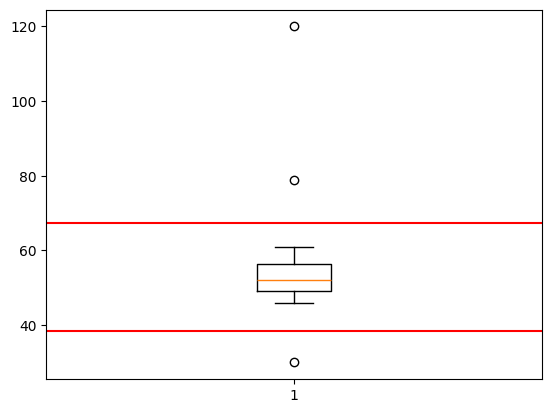

In [11]:
# TODO ข้อ 3
import matplotlib.pyplot as plt
mask,lo,hi=iqr_outliers(sales,1.5)
box=plt.boxplot(sales,whis=1.5)
plt.axhline(lo,color='red')
plt.axhline(hi,color='red')
print([w.get_ydata() for w in box['whiskers']])
print([f.get_ydata() for f in box['fliers']])
print(sales[mask])

## ข้อ 4 · IQR รายกลุ่ม (contextual anomaly) (20 คะแนน)

ค่าจ้างรายเดือน (พันบาท) ของพนักงาน 3 อาชีพ อาชีพละ 8 คน

1. ใช้ `iqr_outliers` กับค่าจ้างทั้ง 24 คนรวมกัน พบ outlier กี่คน
2. ใช้ `groupby('occupation')` คำนวณ IQR แยกแต่ละอาชีพ (ใช้ `.transform` ได้) พบ outlier คนใด
3. ทำตาราง Q1, Q3, IQR, รั้วล่าง, รั้วบน ของแต่ละอาชีพ
4. อธิบายว่าทำไมผลรวมกับผลรายกลุ่มต่างกัน

In [14]:
wage = pd.DataFrame({
    'occupation': ['cleaner']*8 + ['clerk']*8 + ['engineer']*8,
    'wage_k': [12,13,12,14,13,12,15,35,  18,20,19,22,21,20,23,9,  60,65,58,70,62,66,64,61]})

# TODO 4.1
mask_all,lo_all,hi_all=iqr_outliers(wage['wage_k'])
print(mask_all.sum())
print(wage[mask_all])
# TODO 4.2–4.3
g=wage.groupby('occupation')['wage_k']
df_iqr=pd.DataFrame({
    'Q1':g.quantile(0.25),
    'Q3':g.quantile(0.75),
    'IQR':g.quantile(0.75)-g.quantile(0.25),
})
df_iqr['IQR']=df_iqr['Q3']-df_iqr['Q1']
df_iqr['lo']=df_iqr['Q1']-1.5*df_iqr['IQR']
df_iqr['hi']=df_iqr['Q3']+1.5*df_iqr['IQR']
print(df_iqr)

#หาoutlier รายอาชีพ
lo=g.transform('quantile',0.25)-1.5*(g.transform('quantile',0.75)-g.transform('quantile',0.25))
hi=g.transform('quantile',0.75)+1.5*(g.transform('quantile',0.75)-g.transform('quantile',0.25))
print(wage[(wage['wage_k']<lo)|(wage['wage_k']>hi)])

0
Empty DataFrame
Columns: [occupation, wage_k]
Index: []
               Q1     Q3   IQR      lo      hi
occupation                                    
cleaner     12.00  14.25  2.25   8.625  17.625
clerk       18.75  21.25  2.50  15.000  25.000
engineer    60.75  65.25  4.50  54.000  72.000
   occupation  wage_k
7     cleaner      35
15      clerk       9
